# 04 · Evaluation, explainability and governance

Headline metrics are not enough for a pricing sign-off. This notebook answers the questions a pricing committee (and the FCA) would ask:

1. **Is the challenger actually better?** → scorecard, Lorenz curves, *double-lift* chart vs the GLM.
2. **Is it well-calibrated everywhere?** → actual vs predicted by segment.
3. **Why does it price this way?** → SHAP.
4. **Is it safe to use?** → governance & monitoring notes.

Requires notebooks 02 and 03 to have been run.

In [1]:
%load_ext autoreload
%autoreload 2
import warnings

warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import shap

from motor_pricing.config import MODELS_DIR, PROCESSED_DIR, SEED
from motor_pricing.data import load_data, split_data
from motor_pricing.evaluation import (
    double_lift_table, gini, lift_table, lorenz_curve, null_rates, scorecard, segment_calibration,
)
from motor_pricing.features import DRIVAGE_LABELS, VEHAGE_LABELS, add_features, add_glm_bands
from motor_pricing.models import prepare

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.4f}".format)

df = load_data()
train, valid, test = split_data(df)
artifact = joblib.load(MODELS_DIR / "pricing_artifact.joblib")
categories, freq_model = artifact["categories"], artifact["freq"]

order = test["IDpol"]
glm = pd.read_parquet(PROCESSED_DIR / "glm_test_predictions.parquet").set_index("IDpol").loc[order].reset_index(drop=True)
gbm = pd.read_parquet(PROCESSED_DIR / "gbm_test_predictions.parquet").set_index("IDpol").loc[order].reset_index(drop=True)

preds = {
    "Poisson×Gamma GLM": glm[["frequency", "severity", "pure_premium"]],
    "LightGBM freq × sev": gbm[["gbm_frequency", "gbm_severity", "gbm_pure_premium"]].set_axis(
        ["frequency", "severity", "pure_premium"], axis=1),
    "LightGBM Tweedie": gbm[["tweedie_pure_premium"]].set_axis(["pure_premium"], axis=1),
}
loss, expo = test["ClaimAmount"].to_numpy(), test["Exposure"].to_numpy()

## 1. Scorecard

In [2]:
card = scorecard(test, preds, null_rates(train))
card

,freq_poisson_dev,sev_gamma_dev,pp_tweedie_dev,gini,gini_vs_best_possible
null (portfolio average),0.4763,1.4122,78.9311,0.0118,0.0120
Poisson×Gamma GLM,0.4559,1.4182,75.1845,0.3129,0.3183
LightGBM freq × sev,0.4495,1.4060,73.9088,0.3630,0.3692
LightGBM Tweedie,NaN,NaN,74.5658,0.3344,0.3401


### Lorenz curves
The further a curve bows away from the diagonal, the better the model separates good from bad risks.

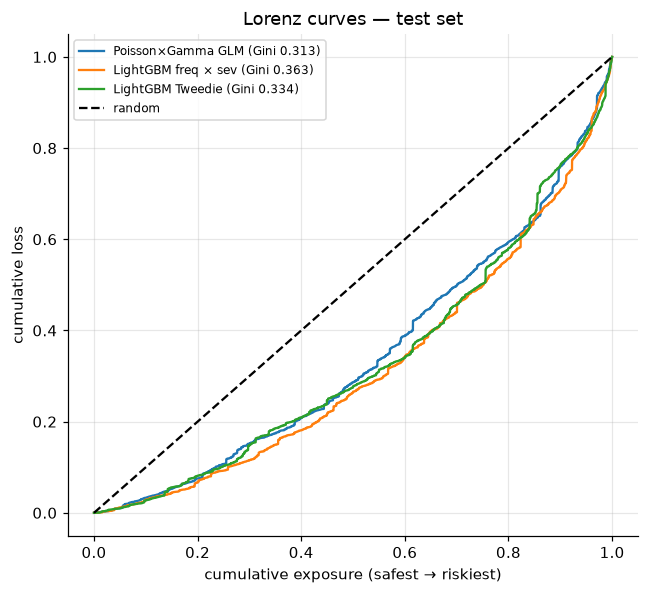

In [3]:
fig, ax = plt.subplots(figsize=(6, 5.5))
for name, p in preds.items():
    x, y = lorenz_curve(loss, p["pure_premium"], expo)
    ax.plot(x, y, label=f"{name} (Gini {gini(loss, p['pure_premium'], expo):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="random")
ax.set(xlabel="cumulative exposure (safest → riskiest)", ylabel="cumulative loss", title="Lorenz curves — test set")
ax.legend(fontsize=8)
plt.tight_layout()

## 2. Lift chart (GBM) and double-lift chart (GBM vs GLM)
* **Lift:** bin policies by *predicted* pure premium into 10 equal-exposure deciles; actual and predicted should rise together and sit on top of each other.
* **Double lift:** sort by the **ratio** GBM ÷ GLM. In the left bins the GBM thinks the GLM *over*-charges, in the right bins that it *under*-charges.
  If the GBM is genuinely better, **actual** losses should follow the GBM line, not the GLM line.

,actual,GLM ÷ actual,GBM ÷ actual
bin,,,
0,93.1714,2.4360,1.4127
1,93.1111,1.6816,1.2259
2,136.1213,1.0587,0.8504
3,126.3230,1.0853,0.9372
4,146.1158,0.9446,0.8691
5,147.6647,0.9146,0.8937
6,115.4319,1.1518,1.1990
7,157.6756,0.8226,0.9229
8,134.0389,0.9968,1.2394


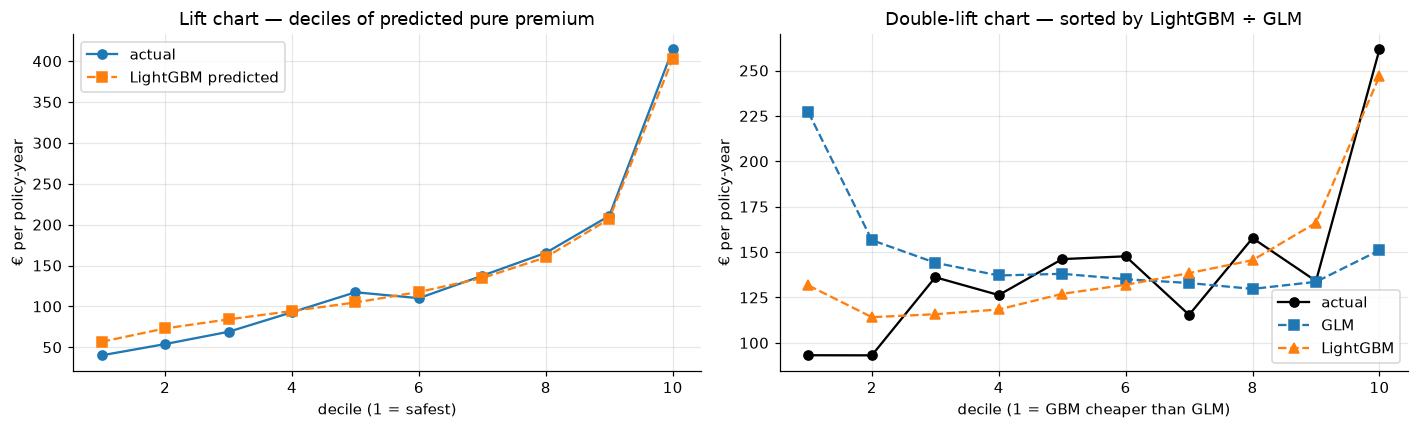

In [4]:
lift = lift_table(loss, expo, preds["LightGBM freq × sev"]["pure_premium"])
dl = double_lift_table(loss, expo, preds["Poisson×Gamma GLM"]["pure_premium"], preds["LightGBM freq × sev"]["pure_premium"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(lift.index + 1, lift["actual_rate"], "o-", label="actual")
axes[0].plot(lift.index + 1, lift["predicted_rate"], "s--", label="LightGBM predicted")
axes[0].set(title="Lift chart — deciles of predicted pure premium", xlabel="decile (1 = safest)", ylabel="€ per policy-year")
axes[0].legend()
axes[1].plot(dl.index + 1, dl["actual"], "o-", color="k", label="actual")
axes[1].plot(dl.index + 1, dl["base_model"], "s--", label="GLM")
axes[1].plot(dl.index + 1, dl["challenger"], "^--", label="LightGBM")
axes[1].set(title="Double-lift chart — sorted by LightGBM ÷ GLM", xlabel="decile (1 = GBM cheaper than GLM)", ylabel="€ per policy-year")
axes[1].legend()
plt.tight_layout()
dl[["actual", "base_vs_actual", "challenger_vs_actual"]].rename(
    columns={"base_vs_actual": "GLM ÷ actual", "challenger_vs_actual": "GBM ÷ actual"})

## 3. Calibration by segment
Aggregate fit can hide segment-level bias. Pure premium per policy-year, actual vs predicted:

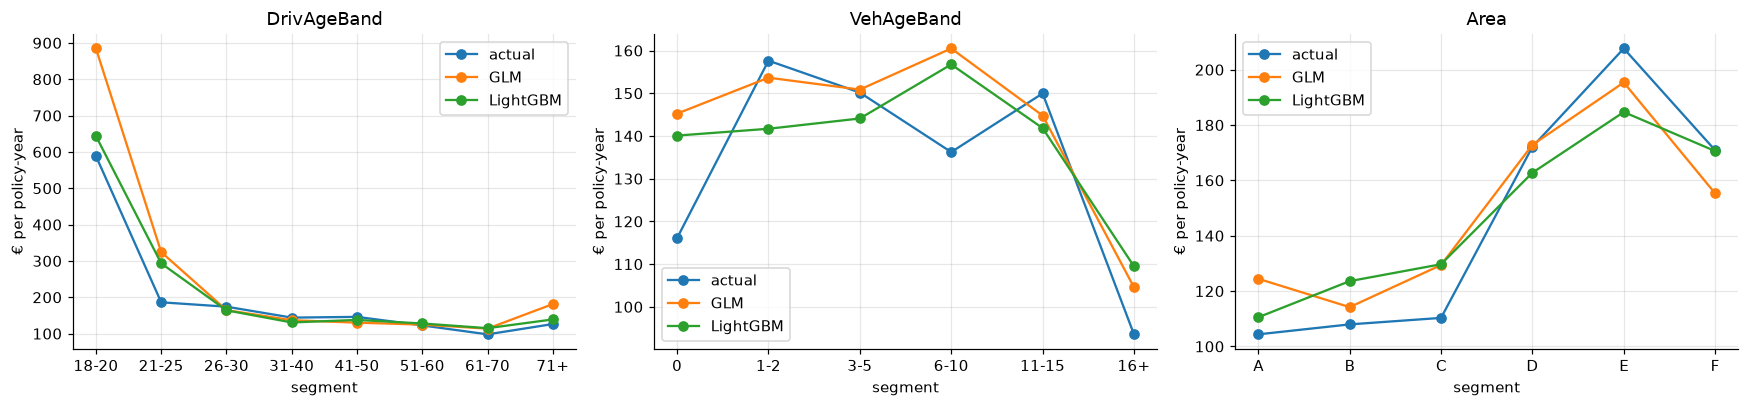

In [5]:
te = add_glm_bands(add_features(test))
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
segments = [("DrivAgeBand", DRIVAGE_LABELS), ("VehAgeBand", VEHAGE_LABELS), ("Area", list("ABCDEF"))]
for ax, (col, lab) in zip(axes, segments, strict=True):
    cal = segment_calibration(
        te[col], loss, expo,
        {"GLM": preds["Poisson×Gamma GLM"]["pure_premium"], "LightGBM": preds["LightGBM freq × sev"]["pure_premium"]},
    ).reindex(lab)
    cal[["actual", "GLM", "LightGBM"]].plot(ax=ax, marker="o", title=col)
    ax.set_ylabel("€ per policy-year")
plt.tight_layout()

## 4. Explainability with SHAP
SHAP values attribute each prediction to the rating factors. They are in **log-frequency** units for this Poisson model, so
`exp(SHAP)` is directly comparable to a GLM relativity. Computed on a sample to keep memory low on an 8 GB machine.

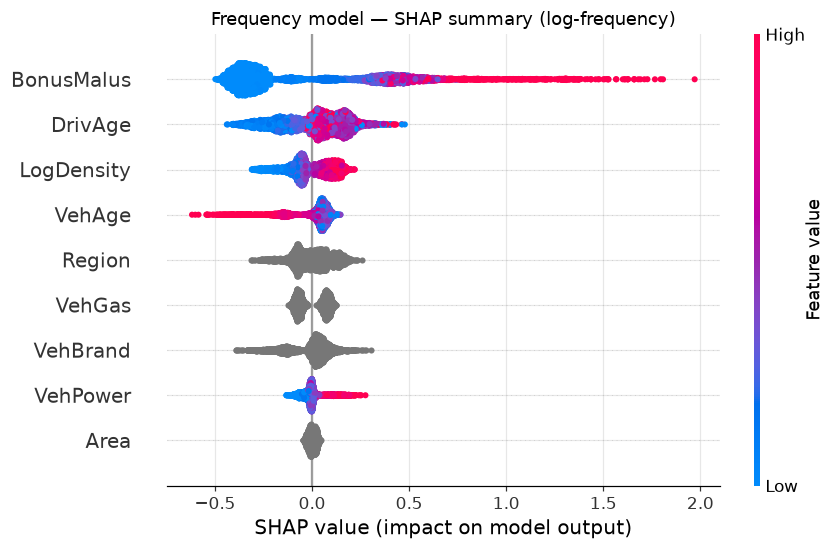

In [6]:
sample = test.sample(min(5000, len(test)), random_state=SEED)
X = prepare(sample, categories)
explainer = shap.TreeExplainer(freq_model)
shap_values = explainer.shap_values(X)
shap.summary_plot(shap_values, X, show=False, max_display=9)
plt.title("Frequency model — SHAP summary (log-frequency)")
plt.tight_layout()

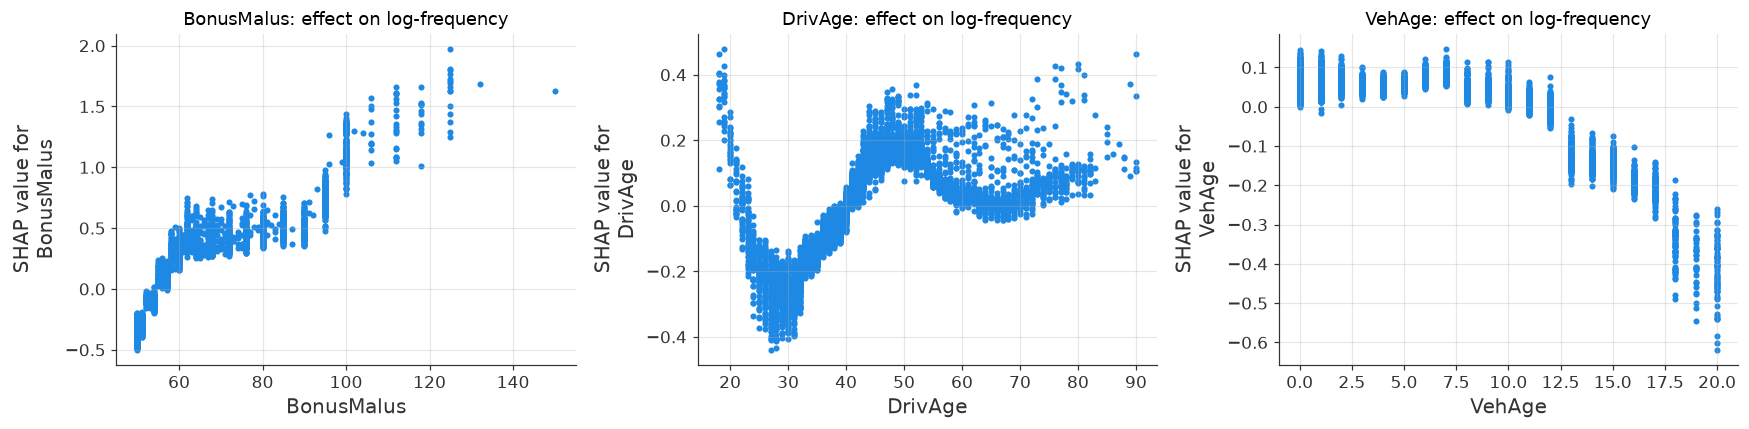

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["BonusMalus", "DrivAge", "VehAge"], strict=True):
    shap.dependence_plot(col, shap_values, X, ax=ax, show=False, interaction_index=None)
    ax.set_title(f"{col}: effect on log-frequency")
plt.tight_layout()

`BonusMalus` is monotone by construction (see notebook 03). `DrivAge` should show the classic **U-shape**: young and very old drivers cost more.
Compare the shapes with the GLM relativities from notebook 02 — agreement builds trust, divergence is where the GBM is finding something extra (or overfitting).

## 5. Model-risk & governance notes (UK context)

| Topic | Notes for this model |
|---|---|
| **Fair value / Consumer Duty (FCA)** | A technical price (pure premium) is *not* a customer price. Expenses, margin and any commercial overlay must be applied transparently and avoid unfair outcomes for customer groups. |
| **Price walking (ICOBS 6B)** | Renewal prices must not exceed the equivalent new-business price (net of channel). Model outputs feed a *rating engine*; the renewal cap is applied downstream. |
| **Protected characteristics** | Sex cannot be a rating factor in UK/EU insurance (Test-Achats ruling). Age is a permitted rating factor but should be justified. Region/density can act as proxies — review for indirect discrimination. |
| **Explainability** | GLM relativities + SHAP summaries give a feature-level story for pricing committees and regulators. |
| **Monotonic constraints** | Encode business rules (bonus-malus) so the model cannot learn counter-intuitive pricing. |
| **Monitoring** | Track feature drift (PSI), actual-vs-expected by segment, Gini decay and loss-ratio by decile monthly. Retrain triggers should be defined *before* go-live. |
| **Data limitations** | French MTPL data (not UK), no date/underwriting year, claim amounts capped at €200k, no telematics/claims-history detail. Treat this as a **methodology demo**, not a rate filing. |

## 6. Summary for your README
Fill in the numbers from your own run:

* GLM Gini = **…**, LightGBM freq×sev Gini = **…**, Tweedie GBM Gini = **…**
* Poisson deviance improvement of GBM over GLM = **…%**
* Double-lift: in the extreme deciles the **… model** tracks actual losses more closely.
* Business interpretation: **…** (e.g. where the GBM would reprice the book).